# 01 — Exploration des événements Bandsintown

**Objectif :** comprendre les données collectées avant de modéliser, et **justifier les choix** faits dans le code :

- le seuil « populaire » à 10 RSVP (`POPULARITY_THRESHOLD`) ;
- les variables explicatives retenues dans `model.py` ;
- le regroupement des petites villes (`MIN_EVENTS_PER_CITY`).

Ce notebook n'envoie **aucune requête** : il lit les pages déjà collectées dans `data/raw/` avec la même fonction que `main.py`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est dans notebooks/ : on se place à la racine du projet
# pour importer le module bandsintown_scraper et lire data/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from bandsintown_scraper.config import MIN_EVENTS_PER_CITY, POPULARITY_THRESHOLD
from bandsintown_scraper.model import build_features
from bandsintown_scraper.transform import load_events_dataframe

In [2]:
from matplotlib.ticker import PercentFormatter

# Style des graphiques : une couleur principale, textes en gris foncé, grille discrète
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e1",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})


def plot_rate(labels, rates, counts, title, xlabel, reference=None):
    """Barres de la part d'événements populaires par catégorie, avec l'effectif sous chaque barre."""
    fig, ax = plt.subplots()
    positions = range(len(labels))
    ax.bar(positions, rates, color=BLUE, width=0.6)
    if reference is not None:
        ax.axhline(reference, color=GRAY, linestyle="--", linewidth=1.5)
        ax.text(len(labels) - 0.5, reference, f"moyenne {reference:.0%}", color="#52514e",
                ha="right", va="bottom", fontsize=9)
    ax.set_xticks(list(positions), [f"{label}\n(n={count})" for label, count in zip(labels, counts)])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("part d'événements populaires")
    plt.tight_layout()
    plt.show()

## 1. Vue d'ensemble

In [3]:
events = load_events_dataframe()
events["est_populaire"] = events["nb_rsvp"] >= POPULARITY_THRESHOLD
print(f"{len(events)} événements, {events['artiste'].nunique()} artistes, {events['lieu'].nunique()} salles")
print(f"du {events['debut'].min():%d/%m/%Y} au {events['debut'].max():%d/%m/%Y}")
events.head()

3892 événements, 2951 artistes, 748 salles
du 23/10/2026 au 30/11/2026


,id,artiste,titre,lieu,localisation,debut,fin,nb_rsvp,url_evenement,streaming,watch_live_text,date_collecte,ville,jour_semaine,est_weekend,numero_semaine,mois,heure,jours_avant_evenement,duree_heures,type_evenement,popularite,longitude,latitude,source_geocodage,est_populaire
0,108878584,Flame Parade,NaN,Bar Italia Records,"Paris, France",2026-10-23 18:00:00,2026-10-23 23:30:00,1,https://www.bandsintown.com/e/108878584-flame-...,False,Watch Live,2026-10-23,Paris,Friday,False,43,10,18,0,5.5,concert,faible,2.320041,48.858890,ville,False
1,109038408,owls woods graves,NaN,Backstage By The Mill,"Paris, France",2026-10-23 18:30:00,NaT,0,https://www.bandsintown.com/e/109038408-owls-w...,False,Watch Live,2026-10-23,Paris,Friday,False,43,10,18,0,NaN,concert,aucune,2.332101,48.884240,salle,False
2,1040582509,Magic Malik Orchestra,NaN,Baiser salé,"Paris 01 Louvre, France",2026-10-23 19:00:00,NaT,0,https://www.bandsintown.com/e/1040582509-magic...,False,Watch Live,2026-10-23,Paris,Friday,False,43,10,19,0,NaN,concert,aucune,2.347805,48.859845,salle,False
3,1039754406,La Mverte,NaN,Bal Chavaux,"Montreuil, France",2026-10-23 19:00:00,NaT,2,https://www.bandsintown.com/e/1039754406-la-mv...,False,Watch Live,2026-10-23,Montreuil,Friday,False,43,10,19,0,NaN,concert,faible,2.435909,48.858720,salle,False
4,108874806,Paris After Six,TAKE TIME - RELEASE PARTY 🚢 PARIS AFTER SIX,Babour Sauvage,"Paris, France",2026-10-23 19:00:00,2026-10-23 23:00:00,0,https://www.bandsintown.com/e/108874806-paris-...,False,Watch Live,2026-10-23,Paris,Friday,False,43,10,19,0,4.0,soirée,aucune,2.392423,48.895155,salle,False


**Valeurs manquantes** (part des événements concernés) :

In [4]:
missing = events.isna().mean().sort_values(ascending=False)
missing[missing > 0].map("{:.1%}".format)

fin             89.1%
duree_heures    89.1%
titre           85.5%
longitude        0.1%
latitude         0.1%
dtype: str

## 2. La cible : le nombre de RSVP

In [5]:
events["nb_rsvp"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1)

count    3892.0
mean        9.0
std        69.3
min         0.0
25%         0.0
50%         0.0
75%         3.0
90%        13.0
99%       123.4
max      2487.0
Name: nb_rsvp, dtype: float64

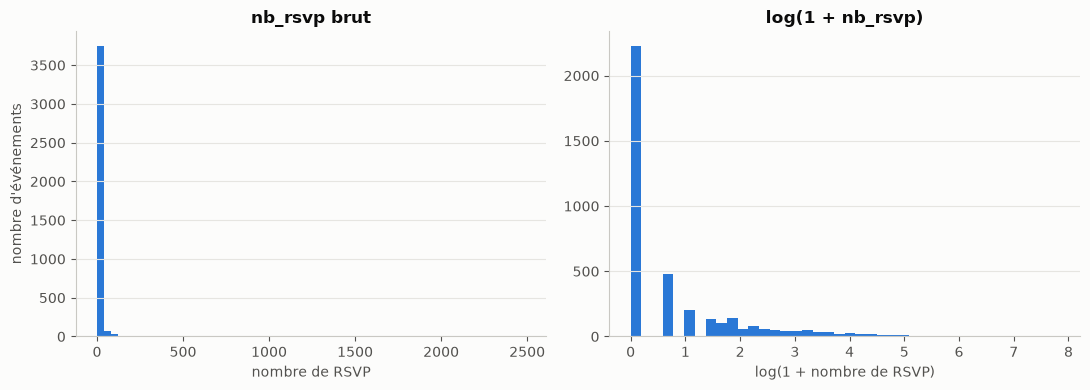

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.hist(events["nb_rsvp"], bins=60, color=BLUE)
left.set_title("nb_rsvp brut")
left.set_xlabel("nombre de RSVP")
left.set_ylabel("nombre d'événements")
right.hist(np.log1p(events["nb_rsvp"]), bins=40, color=BLUE)
right.set_title("log(1 + nb_rsvp)")
right.set_xlabel("log(1 + nombre de RSVP)")
plt.tight_layout()
plt.show()

**Part des événements au-dessus de différents seuils :**

In [7]:
thresholds = [1, 5, 10, 20, 50, 100]
pd.DataFrame({
    "seuil": thresholds,
    "part des événements >= seuil": [f"{(events['nb_rsvp'] >= t).mean():.1%}" for t in thresholds],
    "nombre": [int((events["nb_rsvp"] >= t).sum()) for t in thresholds],
})

,seuil,part des événements >= seuil,nombre
0,1,42.8%,1664
1,5,19.2%,749
2,10,12.0%,468
3,20,7.5%,292
4,50,3.2%,126
5,100,1.3%,52


## 3. Popularité selon l'heure de l'événement

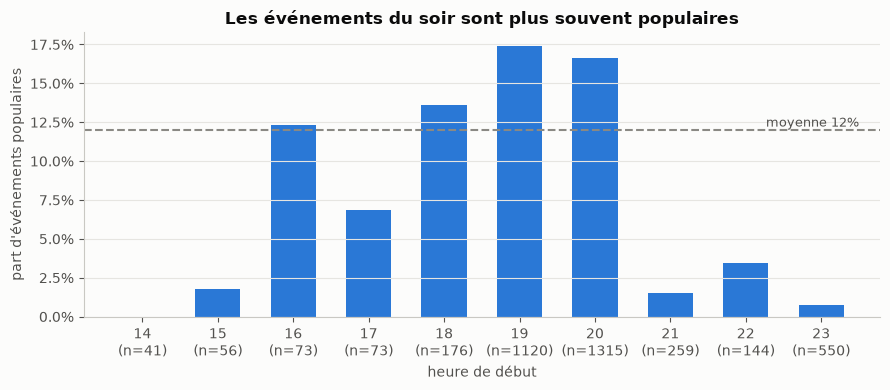

In [8]:
base_rate = events["est_populaire"].mean()
by_hour = events.groupby("heure")["est_populaire"].agg(["mean", "size"])
by_hour = by_hour[by_hour["size"] >= 30]  # heures avec trop peu d'événements écartées
plot_rate(by_hour.index, by_hour["mean"], by_hour["size"],
          "Les événements du soir sont plus souvent populaires", "heure de début", base_rate)

## 4. Popularité selon le jour de la semaine

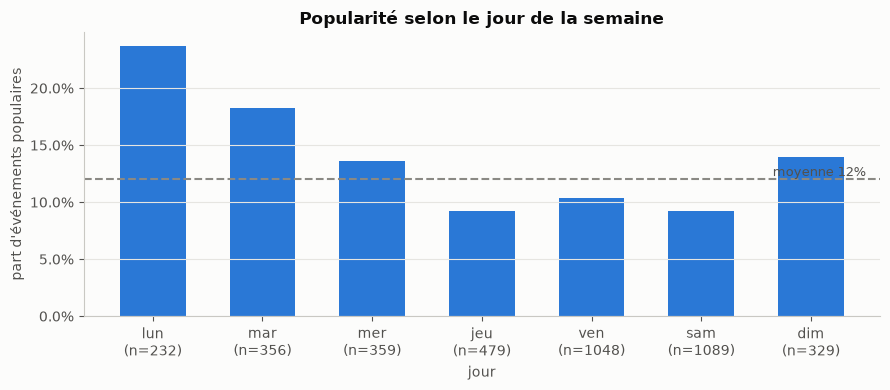

In [9]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
labels_fr = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
by_day = events.groupby("jour_semaine")["est_populaire"].agg(["mean", "size"]).reindex(days)
plot_rate(labels_fr, by_day["mean"], by_day["size"],
          "Popularité selon le jour de la semaine", "jour", base_rate)

## 5. Popularité selon le type d'événement

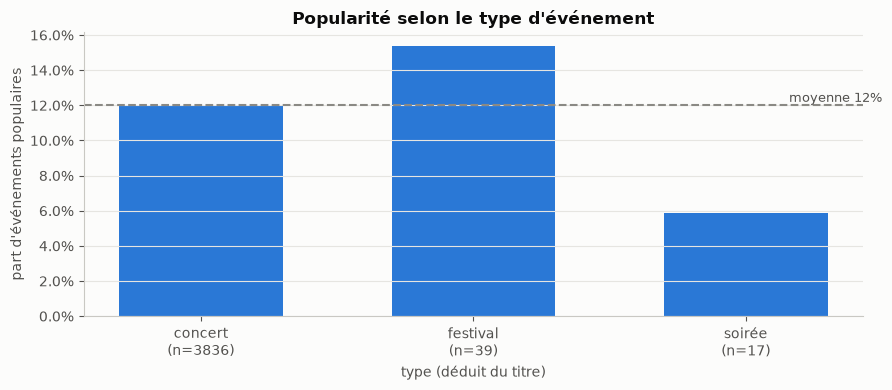

In [10]:
by_type = events.groupby("type_evenement")["est_populaire"].agg(["mean", "size"]).sort_values("size", ascending=False)
plot_rate(by_type.index, by_type["mean"], by_type["size"],
          "Popularité selon le type d'événement", "type (déduit du titre)", base_rate)

## 6. Popularité selon la distance au centre de Paris

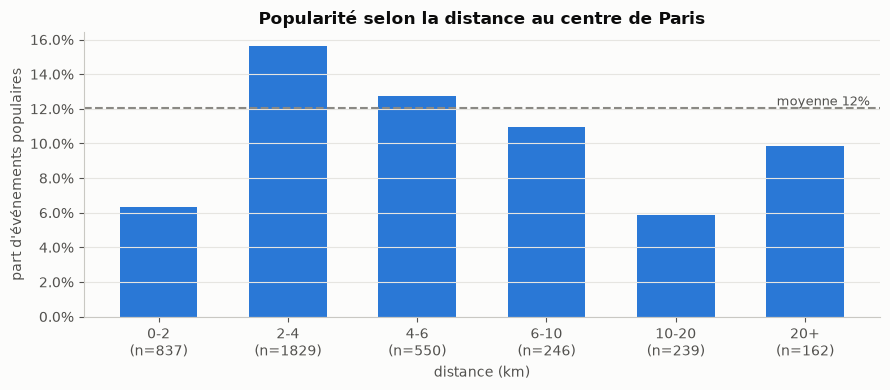

In [11]:
features, _ = build_features(events)
distance_bins = pd.cut(features["distance_centre_km"], [0, 2, 4, 6, 10, 20, 60],
                       labels=["0-2", "2-4", "4-6", "6-10", "10-20", "20+"])
by_distance = events.groupby(distance_bins, observed=True)["est_populaire"].agg(["mean", "size"])
plot_rate(by_distance.index, by_distance["mean"], by_distance["size"],
          "Popularité selon la distance au centre de Paris", "distance (km)", base_rate)

## 7. Popularité selon l'activité de l'artiste et de la salle

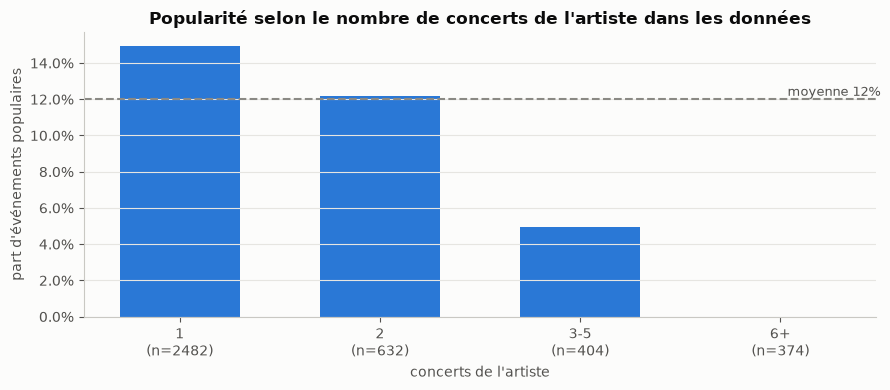

In [12]:
artist_bins = pd.cut(features["nb_evenements_artiste"], [0, 1, 2, 5, 1000], labels=["1", "2", "3-5", "6+"])
by_artist = events.groupby(artist_bins, observed=True)["est_populaire"].agg(["mean", "size"])
plot_rate(by_artist.index, by_artist["mean"], by_artist["size"],
          "Popularité selon le nombre de concerts de l'artiste dans les données",
          "concerts de l'artiste", base_rate)

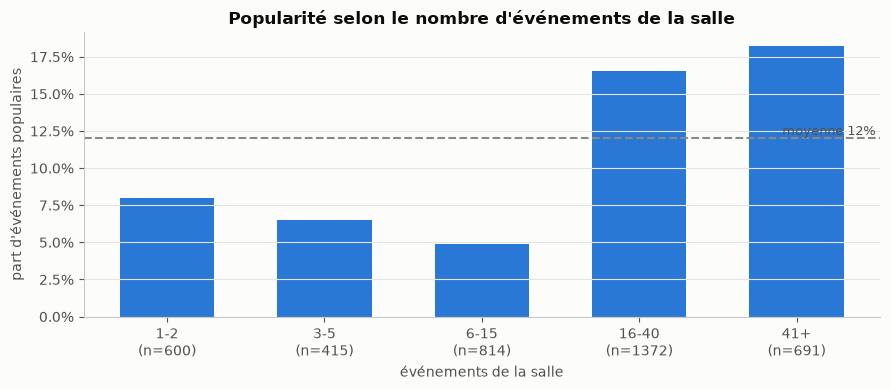

In [13]:
venue_bins = pd.cut(features["nb_evenements_salle"], [0, 2, 5, 15, 40, 1000], labels=["1-2", "3-5", "6-15", "16-40", "41+"])
by_venue = events.groupby(venue_bins, observed=True)["est_populaire"].agg(["mean", "size"])
plot_rate(by_venue.index, by_venue["mean"], by_venue["size"],
          "Popularité selon le nombre d'événements de la salle", "événements de la salle", base_rate)

## 8. Les villes

In [14]:
cities = events["ville"].value_counts()
print(f"{len(cities)} villes différentes ; {(cities < MIN_EVENTS_PER_CITY).sum()} ont moins de "
      f"{MIN_EVENTS_PER_CITY} événements (regroupées dans « autres » par le modèle)")
cities.head(10)

195 villes différentes ; 190 ont moins de 20 événements (regroupées dans « autres » par le modèle)


ville
Paris                   3172
Montreuil                 90
Pantin                    57
Villepinte                49
Massy                     33
Boulogne-Billancourt      19
Nanterre                  17
Bagnolet                  16
Versailles                13
Ris-Orangis               12
Name: count, dtype: int64

## 9. Conclusions

Chiffres de la collecte du 23/10/2026 (3892 événements).

**La cible**
- `nb_rsvp` est extrêmement asymétrique : médiane à 0, 57 % des événements sans aucun RSVP, mais un maximum à 2487.
- **Seuil « populaire » à 10 RSVP** : il concerne 12 % des événements (468). C'est assez rare pour désigner de vrais succès, et assez fréquent pour que le modèle ait des exemples à apprendre. Au seuil de 50, il n'en resterait que 126.
- **Classes déséquilibrées** (12 % contre 88 %) : l'accuracy serait trompeuse, d'où le ROC-AUC, le F1 et `class_weight="balanced"` dans `model.py`.

**Ce qui est lié à la popularité**
- **L'heure est le signal le plus net** : environ 17-18 % d'événements populaires à 19h-20h, contre 1 à 3 % après 21h (soirées et DJ sets).
- **La salle compte** : les salles qui accueillent beaucoup d'événements (plus de 15) ont 16 à 18 % d'événements populaires, contre 5 à 8 % pour les petites salles.
- **La distance au centre n'a pas un effet régulier** : 6 % à moins de 2 km (petits bars du centre), 16 % entre 2 et 4 km, puis une baisse. Un modèle linéaire capte mal ce genre d'effet, d'où l'intérêt des modèles à base d'arbres.
- **Le nombre de dates de l'artiste joue à l'envers de l'intuition** : plus un artiste a de dates dans les données, *moins* ses événements sont populaires (0 % au-delà de 5 dates). Ce sont surtout des spectacles qui se répètent (comédies musicales, résidences), où chaque date attire peu de RSVP. Cette variable est utile au modèle, mais elle **ne mesure pas la notoriété**.
- **Le week-end n'est pas plus populaire** (10 % contre 13 % en semaine). Le lundi (24 %) et le mardi (18 %) ont les taux les plus élevés, mais sur peu d'événements.
- **Le type d'événement apporte peu** : 85 % des titres sont vides, donc 98 % des événements sont classés « concert ».

**Qualité des données**
- `fin` et `duree_heures` manquent pour 89 % des événements : la durée n'est pas utilisée par le modèle.
- Les coordonnées GPS manquent pour moins de 0,2 % des événements : elles sont complétées par la médiane dans le modèle.
- 195 villes, dont 190 avec moins de 20 événements : le regroupement en « autres » (`MIN_EVENTS_PER_CITY`) évite 190 colonnes presque vides.